In [14]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
dados = sns.load_dataset('diamonds')
dados.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


1. Carregue o dataset e analise as estatísticas descritivas das colunas numéricas. Consulte o
significado das colunas x, y e z. Algum valor é fisicamente impossível?

In [7]:
dados.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [9]:
dados[(dados[['x', 'y', 'z']] <= 0).any(axis=1)]

,carat,cut,color,clarity,depth,table,price,x,y,z
2207,1.00,Premium,G,SI2,59.1,59.0,3142,6.55,6.48,0.0
2314,1.01,Premium,H,I1,58.1,59.0,3167,6.66,6.60,0.0
4791,1.10,Premium,G,SI2,63.0,59.0,3696,6.50,6.47,0.0
5471,1.01,Premium,F,SI2,59.2,58.0,3837,6.50,6.47,0.0
10167,1.50,Good,G,I1,64.0,61.0,4731,7.15,7.04,0.0
11182,1.07,Ideal,F,SI2,61.6,56.0,4954,0.00,6.62,0.0
11963,1.00,Very Good,H,VS2,63.3,53.0,5139,0.00,0.00,0.0
13601,1.15,Ideal,G,VS2,59.2,56.0,5564,6.88,6.83,0.0
15951,1.14,Fair,G,VS1,57.5,67.0,6381,0.00,0.00,0.0
24394,2.18,Premium,H,SI2,59.4,61.0,12631,8.49,8.45,0.0


In [10]:
dados[(dados['y'] > 20) | (dados['z'] > 10)]

,carat,cut,color,clarity,depth,table,price,x,y,z
24067,2.00,Premium,H,SI2,58.9,57.0,12210,8.09,58.90,8.06
48410,0.51,Very Good,E,VS1,61.8,54.7,1970,5.12,5.15,31.80
49189,0.51,Ideal,E,VS1,61.8,55.0,2075,5.15,31.80,5.12


In [11]:
dados.loc[[24067, 48410, 49189]]

,carat,cut,color,clarity,depth,table,price,x,y,z
24067,2.00,Premium,H,SI2,58.9,57.0,12210,8.09,58.90,8.06
48410,0.51,Very Good,E,VS1,61.8,54.7,1970,5.12,5.15,31.80
49189,0.51,Ideal,E,VS1,61.8,55.0,2075,5.15,31.80,5.12


As colunas `x`, `y` e `z` representam o comprimento, a largura e a profundidade dos diamantes, em milímetros. Identifiquei valores iguais a zero, que são fisicamente impossíveis. Também encontrei valores extremos, como `y = 58,90` e `z = 31,80`, em diamantes de dimensões e pesos muito menores. Ao comparar as medidas, esses valores parecem ser erros de registro, pois não são compatíveis com as outras dimensões dos diamantes.

2. Detecte outliers em cada coluna numérica usando dois métodos: Z-score e IQR. Compare
quantos registros cada método aponta.

In [12]:
#Z-score
from scipy.stats import zscore

numericas = dados.select_dtypes(include='number')

z_scores = numericas.apply(lambda coluna: np.abs(zscore(coluna)))

outliers_z = z_scores > 3

outliers_z.sum()


,0
carat,439
depth,685
table,336
price,1206
x,43
y,34
z,55


In [13]:
#IQR
q1 = numericas.quantile(0.25)
q3 = numericas.quantile(0.75)

iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers_iqr = (numericas < limite_inferior) | (numericas > limite_superior)

outliers_iqr.sum()

,0
carat,1889
depth,2545
table,605
price,3540
x,32
y,29
z,49


* Z-score: considera a distância em relação à média e ao desvio padrão.

* IQR: considera os quartis.

Assim, o IQR identificou mais outliers do que o Z-score nas colunas `carat`, `depth`, `table` e `price`. Já nas colunas `x`, `y` e `z`, o Z-score identificou mais valores extremos. Ou seja, os outliers dependem da distribuição dos dados e  do método ultilizado.

3. Visualize os outliers com boxplots e gráficos de dispersão (escolha pares de colunas que façam
sentido juntos).

In [15]:
numericas = dados.select_dtypes(include='number')

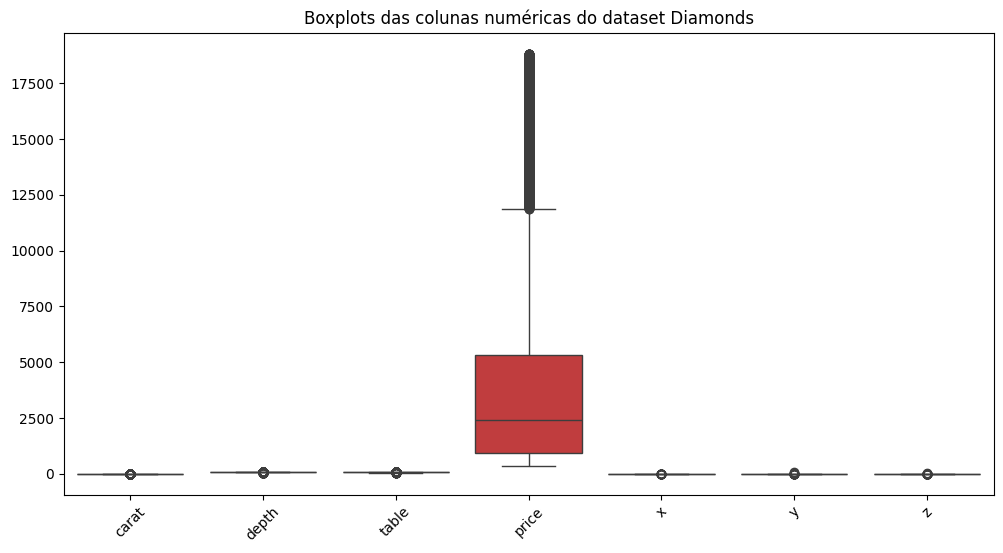

In [16]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=numericas)
plt.title('Boxplots das colunas numéricas do dataset Diamonds')
plt.xticks(rotation=45)
plt.show()

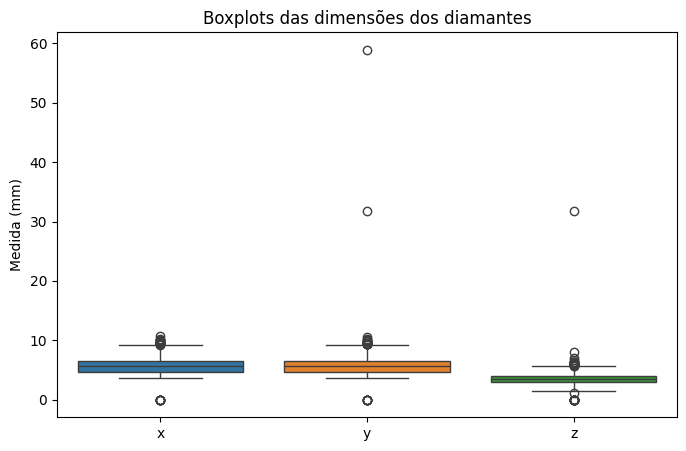

In [17]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=dados[['x', 'y', 'z']])
plt.title('Boxplots das dimensões dos diamantes')
plt.ylabel('Medida (mm)')
plt.show()

Os boxplots mostram valores extremos na coluna `price` e nas dimensões `x`, `y` e `z`.

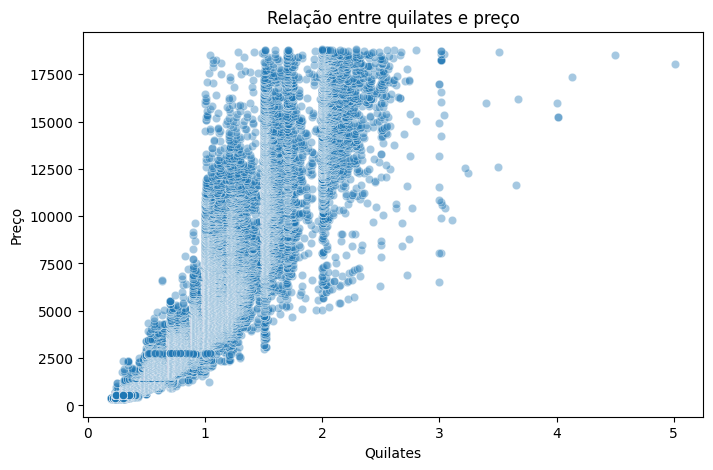

In [18]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=dados, x='carat', y='price', alpha=0.4)
plt.title('Relação entre quilates e preço')
plt.xlabel('Quilates')
plt.ylabel('Preço')
plt.show()


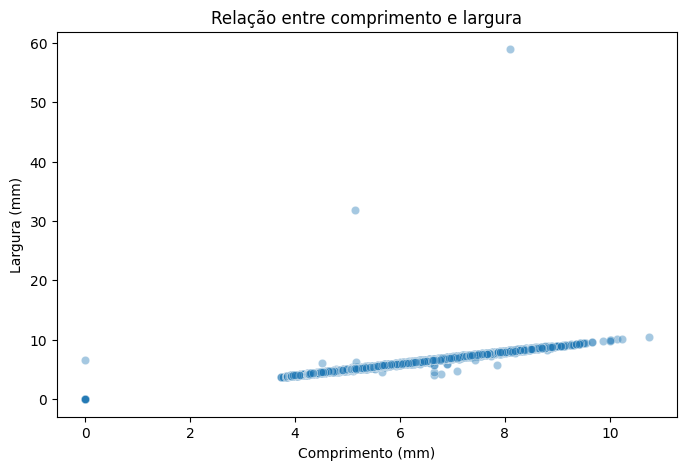

In [20]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=dados, x='x', y='y', alpha=0.4)
plt.title('Relação entre comprimento e largura')
plt.xlabel('Comprimento (mm)')
plt.ylabel('Largura (mm)')
plt.show()

No gráfico de dispersão entre quilates e preço, geralmente, diamantes com mais quilates apresentam preços maiores.

No gráfico entre comprimento e largura, a maioria dos pontos segue um padrão crescente, mas existem valores muito distantes dos demais e medidas iguais a zero. Esses casos devem ser investigados, pois podem indicar erros de registro. Entretanto, nem todo outlier é um erro, já que alguns diamantes podem ter características raras e legítimas.



4. Classifique o que você encontrou: o que é erro de registro e o que é valor extremo legítimo?
Explique o critério usado.

As dimensões iguais a zero são erros de registro, pois é fisicamente impossível. Além disso, as dimensões muito altas são possíveis erros, já que fogem de pesos e medidas reais de um diamante.

Preços elevados e valores maiores de quilates não devem ser considerados erros, tendo em vista que, podem representar diamantes maiores e mais valiosos.

Os casos suspeitos devem ser investigados antes que sejam removidos.

5. Aplique três estratégias de tratamento — remoção, capping (substituição pelos limites) e
transformação (log ou raiz quadrada) — e compare o impacto nas estatísticas descritivas e na
distribuição de price.

In [21]:
#Remoção
q1 = dados['price'].quantile(0.25)
q3 = dados['price'].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

dados_sem_outliers = dados[
    (dados['price'] >= limite_inferior) &
    (dados['price'] <= limite_superior)
]

dados_sem_outliers['price'].describe()

,price
count,50400.000000
mean,3159.460833
std,2764.700316
min,326.000000
25%,911.000000
50%,2155.000000
75%,4669.000000
max,11883.000000


In [22]:
#Comparação
print("Registros originais:", len(dados))
print("Registros após remoção:", len(dados_sem_outliers))
print("Registros removidos:", len(dados) - len(dados_sem_outliers))

Registros originais: 53940
Registros após remoção: 50400
Registros removidos: 3540


In [23]:
#Capping
dados_capping = dados.copy()

dados_capping['price'] = dados_capping['price'].clip(
    lower=limite_inferior,
    upper=limite_superior
)

dados_capping['price'].describe()

,price
count,53940.000000
mean,3732.145690
std,3436.769344
min,326.000000
25%,950.000000
50%,2401.000000
75%,5324.250000
max,11885.625000


In [24]:
print("Registros originais:", len(dados))
print("Registros após capping:", len(dados_capping))
print("Limite inferior:", limite_inferior)
print("Limite superior:", limite_superior)

Registros originais: 53940
Registros após capping: 53940
Limite inferior: -5611.375
Limite superior: 11885.625


In [25]:
#Transformação
dados_log = dados.copy()

dados_log['price'] = np.log(dados_log['price'])

dados_log['price'].describe()

,price
count,53940.000000
mean,7.786768
std,1.014649
min,5.786897
25%,6.856462
50%,7.783641
75%,8.580027
max,9.842835


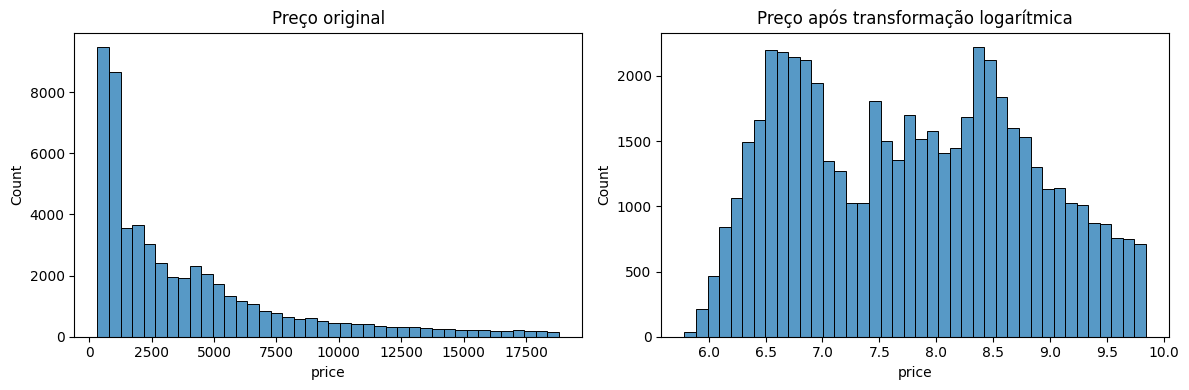

In [26]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(dados['price'], bins=40, ax=eixos[0])
eixos[0].set_title('Preço original')

sns.histplot(dados_log['price'], bins=40, ax=eixos[1])
eixos[1].set_title('Preço após transformação logarítmica')

plt.tight_layout()
plt.show()

In [27]:
comparacao_price = pd.DataFrame({
    'Original': dados['price'].describe(),
    'Remoção': dados_sem_outliers['price'].describe(),
    'Capping': dados_capping['price'].describe(),
    'Log': dados_log['price'].describe()
})

comparacao_price.round(2)

,Original,Remoção,Capping,Log
count,53940.00,50400.00,53940.00,53940.00
mean,3932.80,3159.46,3732.15,7.79
std,3989.44,2764.70,3436.77,1.01
min,326.00,326.00,326.00,5.79
25%,950.00,911.00,950.00,6.86
50%,2401.00,2155.00,2401.00,7.78
75%,5324.25,4669.00,5324.25,8.58
max,18823.00,11883.00,11885.62,9.84


- Remoção: Foram removidos 3.540 registros, reduzindo a média do preço de 3.932,80 para 3.159,46 e o valor máximo de 18.823 para 11.883.

- Capping: Todos os registros foram mantidos, mas os preços extremos foram limitados. A média caiu para 3.732,15 e o valor máximo passou para 11.885,63.

- Transformação logarítmica: Todos os registros foram mantidos e os valores altos foram comprimidos, reduzindo a assimetria da distribuição. A média passou para 7,79 e o desvio-padrão para 1,01, agora na escala logarítmica.

**Para refletir:**

* O Z-score parte de uma suposição sobre a forma da distribuição. Qual? Essa suposição vale
para price? Mostre com um gráfico.

O Z-score funciona melhor quando os dados seguem aproximadamente uma distribuição normal, em formato de sino. A coluna price não segue esse padrão, pois apresenta assimetria à direita, com muitos preços baixos e poucos preços muito altos.

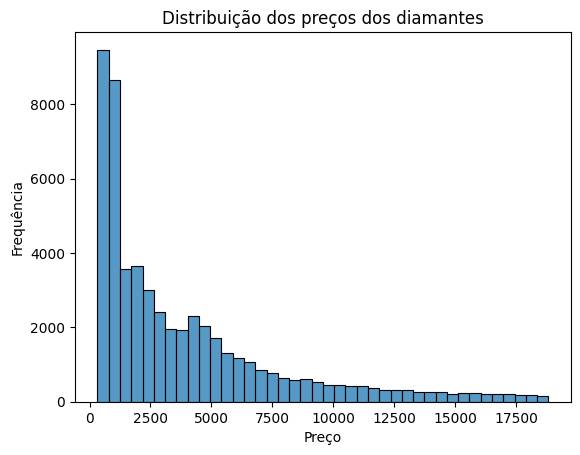

In [28]:
sns.histplot(data=dados, x='price', bins=40)
plt.title('Distribuição dos preços dos diamantes')
plt.xlabel('Preço')
plt.ylabel('Frequência')
plt.show()

* Um diamante de mais de 4 quilates é um outlier a ser removido ou um diamante raro?
Como o objetivo da análise muda essa resposta?

Um diamante com mais de 4 quilates pode ser raro, mas não necessariamente é um erro. Se o objetivo for analisar diamantes comuns, ele pode ser tratado separadamente. Porém, se a intenção for estudar diamantes raros ou de alto valor, removê-lo faria perder uma informação importante.

* Dê um exemplo de situação em que remover outliers esconderia exatamente aquilo que o
negócio quer descobrir.

Em uma joalheria, remover todos os diamantes com preços muito altos poderia esconder justamente os produtos mais valiosos e raros, que são importantes para entender o mercado de luxo. Portanto, é necessário avaliar os valores extremos antes de removê-los.